## Step 0.1 — Environment and Library Versions

In [11]:
import sys

import matplotlib
import numpy
import pandas
import sklearn

print(sys.version.split()[0], numpy.__version__, pandas.__version__, sklearn.__version__, matplotlib.__version__)

3.13.1 2.3.4 2.3.3 1.7.2 3.10.7


## Step 0.2 — Dataset Loading and Train-Test Split

In [12]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 3113

data = pd.read_csv("data/spambase.csv")

feature_names = [c for c in data.columns if c != "spam"]

X, y = data[feature_names].to_numpy(), data["spam"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    stratify=y,
    random_state=SEED
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

print(X.shape, round(100 * y.mean(), 1), X_train.shape, X_test.shape)

(4204, 57) 39.9 (3153, 57) (1051, 57)


The dataset contains 4,204 emails and 57 numerical features. About 39.9% of the emails are classified as spam. The data was divided into a training set with 3,153 emails (75%) and a test set with 1,051 emails (25%).

## Step 0.3 — Model Definitions

In [13]:
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=SEED)

bag = BaggingClassifier(
    DecisionTreeClassifier(),
    n_estimators=100,
    oob_score=True,
    random_state=SEED
)

rf = RandomForestClassifier(
    n_estimators=300,
    oob_score=True,
    random_state=SEED,
    n_jobs=-1
)

lr = make_pipeline(
    FunctionTransformer(np.log1p),
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

bag_lr = BaggingClassifier(
    lr,
    n_estimators=50,
    random_state=SEED
)

knn = make_pipeline(
    FunctionTransformer(np.log1p),
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=15)
)

ada = AdaBoostClassifier(
    n_estimators=400,
    random_state=SEED
)

members = [("lr", lr), ("knn", knn), ("tree", tree)]

print("All models have been defined successfully.")

All models have been defined successfully.


# Part 1 — Bagging and Out-of-Bag Estimates 

## Step 1.1 — Implementing the OOB Mask Function

In [15]:
def oob_mask(sample_indices, n_samples):
    """Return a boolean mask of samples not included in the bootstrap sample."""
    mask = np.ones(n_samples, dtype=bool)
    mask[np.asarray(sample_indices, dtype=int)] = False
    return mask



print(oob_mask([0, 2, 2], 5))
print(oob_mask([], 3))
print(oob_mask(np.array([3, 0]), 4))

[False  True False  True  True]
[ True  True  True]
[False  True  True False]




The `oob_mask` function identifies which training samples were not selected in a bootstrap sample. It returns `True` for samples that were not used and `False` for samples that were selected.



## Step 1.2 — Out-of-Bag Share Calculation

In [16]:

bag.fit(X_train, y_train)

n = len(X_train)

oob_shares = []

for sample_indices in bag.estimators_samples_:
    mask = oob_mask(sample_indices, n)
    oob_shares.append(mask.mean())

# Average shares
mean_oob_share = np.mean(oob_shares)
mean_inbag_share = 1 - mean_oob_share

# Theoretical probabilities
theoretical_oob = (1 - 1 / n) ** n
theoretical_inbag = 1 - theoretical_oob

print(f"Number of training samples: {n}")
print(f"Number of trees: {len(bag.estimators_)}")

print(f"\nMean OOB share: {mean_oob_share:.4f}")
print(f"Mean in-bag share: {mean_inbag_share:.4f}")

print(f"\nTheoretical OOB share: {theoretical_oob:.4f}")
print(f"Theoretical in-bag share: {theoretical_inbag:.4f}")

print(f"\nDifference: {abs(mean_oob_share - theoretical_oob):.6f}")

Number of training samples: 3153
Number of trees: 100

Mean OOB share: 0.3680
Mean in-bag share: 0.6320

Theoretical OOB share: 0.3678
Theoretical in-bag share: 0.6322

Difference: 0.000133


## Step 1.3 — Calculating OOB Accuracy Manually

In [17]:

n = len(X_train)
votes = np.zeros((n, 2), dtype=int)


for tree_model, sample_indices in zip(
    bag.estimators_, bag.estimators_samples_
):
    mask = oob_mask(sample_indices, n)

    predictions = tree_model.predict(X_train[mask])

    row_indices = np.where(mask)[0]
    for row, prediction in zip(row_indices, predictions):
        votes[row, int(prediction)] += 1


oob_predictions = np.argmax(votes, axis=1)

valid_rows = votes.sum(axis=1) > 0
manual_oob_accuracy = np.mean(
    oob_predictions[valid_rows] == y_train[valid_rows]
)

print(f"Manual OOB accuracy: {manual_oob_accuracy:.4f}")
print(f"Sklearn OOB accuracy: {bag.oob_score_:.4f}")
print(f"Difference: {abs(manual_oob_accuracy - bag.oob_score_):.6f}")
print(f"Rows with no OOB votes: {(~valid_rows).sum()}")

Manual OOB accuracy: 0.9375
Sklearn OOB accuracy: 0.9375
Difference: 0.000000
Rows with no OOB votes: 0


## Step 1.4 — Five-Fold Cross-Validation

In [8]:
from sklearn.model_selection import cross_validate


models = {
    "Decision Tree": tree,
    "Bagging Tree": bag,
    "Random Forest": rf,
    "Logistic Regression": lr,
    "Bagging LR": bag_lr
}


cv_scores = {}

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy"
    )["test_score"]

    cv_scores[name] = scores


results = []

for name, scores in cv_scores.items():
    results.append({
        "Model": name,
        "Fold 1": scores[0],
        "Fold 2": scores[1],
        "Fold 3": scores[2],
        "Fold 4": scores[3],
        "Fold 5": scores[4],
        "Mean": np.mean(scores),
        "Std": np.std(scores, ddof=0)
    })

cv_table = pd.DataFrame(results)

display(cv_table.round(4))

,Model,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,Std
0,Decision Tree,0.8875,0.9049,0.9128,0.8968,0.9143,0.9033,0.0101
1,Bagging Tree,0.9445,0.9319,0.9271,0.9302,0.9429,0.9353,0.0070
2,Random Forest,0.9540,0.9429,0.9382,0.9444,0.9508,0.9461,0.0057
3,Logistic Regression,0.9477,0.9429,0.9366,0.9365,0.9444,0.9416,0.0044
4,Bagging LR,0.9477,0.9398,0.9350,0.9413,0.9444,0.9416,0.0043


## Step 1.5 — Paired Fold Differences

In [10]:

comparisons = {
    "Bagging Tree - Decision Tree":
        cv_scores["Bagging Tree"] - cv_scores["Decision Tree"],

    "Random Forest - Decision Tree":
        cv_scores["Random Forest"] - cv_scores["Decision Tree"],

    "Bagging LR - Logistic Regression":
        cv_scores["Bagging LR"] - cv_scores["Logistic Regression"]
}

difference_results = []

for name, differences in comparisons.items():
    mean_diff = np.mean(differences)
    std_diff = np.std(differences, ddof=0)

    if abs(mean_diff) <= std_diff:
        conclusion = "Inside fold spread (no clear winner)"
    elif mean_diff > 0:
        conclusion = "First model performs better"
    else:
        conclusion = "Second model performs better"

    difference_results.append({
        "Comparison": name,
        "Fold 1": differences[0],
        "Fold 2": differences[1],
        "Fold 3": differences[2],
        "Fold 4": differences[3],
        "Fold 5": differences[4],
        "Mean Difference": mean_diff,
        "Std Difference": std_diff,
        "Conclusion": conclusion
    })

difference_table = pd.DataFrame(difference_results)

display(difference_table.round(4))

,Comparison,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean Difference,Std Difference,Conclusion
0,Bagging Tree - Decision Tree,0.0571,0.0269,0.0143,0.0333,0.0286,0.0320,0.0140,First model performs better
1,Random Forest - Decision Tree,0.0666,0.0380,0.0254,0.0476,0.0365,0.0428,0.0138,First model performs better
2,Bagging LR - Logistic Regression,0.0000,-0.0032,-0.0016,0.0048,0.0000,0.0000,0.0027,Inside fold spread (no clear winner)


## Step 1.6 — Random Forest: OOB, CV and Test Accuracy

In [18]:
from sklearn.metrics import accuracy_score


rf.fit(X_train, y_train)

rf_oob = rf.oob_score_

rf_cv_scores = cv_scores["Random Forest"]
rf_cv_mean = np.mean(rf_cv_scores)
rf_cv_std = np.std(rf_cv_scores, ddof=0)

rf_test_predictions = rf.predict(X_test)
rf_test_accuracy = accuracy_score(y_test, rf_test_predictions)


n_test = len(y_test)
standard_error = np.sqrt(
    rf_test_accuracy * (1 - rf_test_accuracy) / n_test
)


difference = abs(rf_oob - rf_cv_mean)
agreement = difference <= rf_cv_std

print(f"Random Forest OOB accuracy: {rf_oob:.4f}")
print(f"Random Forest CV mean accuracy: {rf_cv_mean:.4f}")
print(f"Random Forest CV std: {rf_cv_std:.4f}")
print(f"Random Forest test accuracy: {rf_test_accuracy:.4f}")
print(f"Test standard error: {standard_error:.4f}")

print(f"\nOOB-CV difference: {difference:.4f}")
print(f"OOB and CV agree: {agreement}")

Random Forest OOB accuracy: 0.9486
Random Forest CV mean accuracy: 0.9461
Random Forest CV std: 0.0057
Random Forest test accuracy: 0.9429
Test standard error: 0.0072

OOB-CV difference: 0.0025
OOB and CV agree: True


### Interpretation

The Random Forest model achieved an OOB accuracy of 94.86%, a mean cross-validation accuracy of 94.61%, and a test accuracy of 94.29%. These results are close to each other, which suggests that the model performs consistently on different data.

The standard deviation of the cross-validation scores was 0.0057, while the standard error of the test accuracy was 0.0072.

The difference between OOB and CV accuracy was 0.0025, which is smaller than the CV standard deviation of 0.0057. Therefore, the OOB and CV results are in agreement.

Overall, OOB accuracy is a reasonable estimate of cross-validation performance for this Random Forest model. The test accuracy is slightly lower, but the difference is small compared with its standard error.

# Part 2 — Evaluating the Filter 

## Step 2.1 — ROC and Precision-Recall Curves

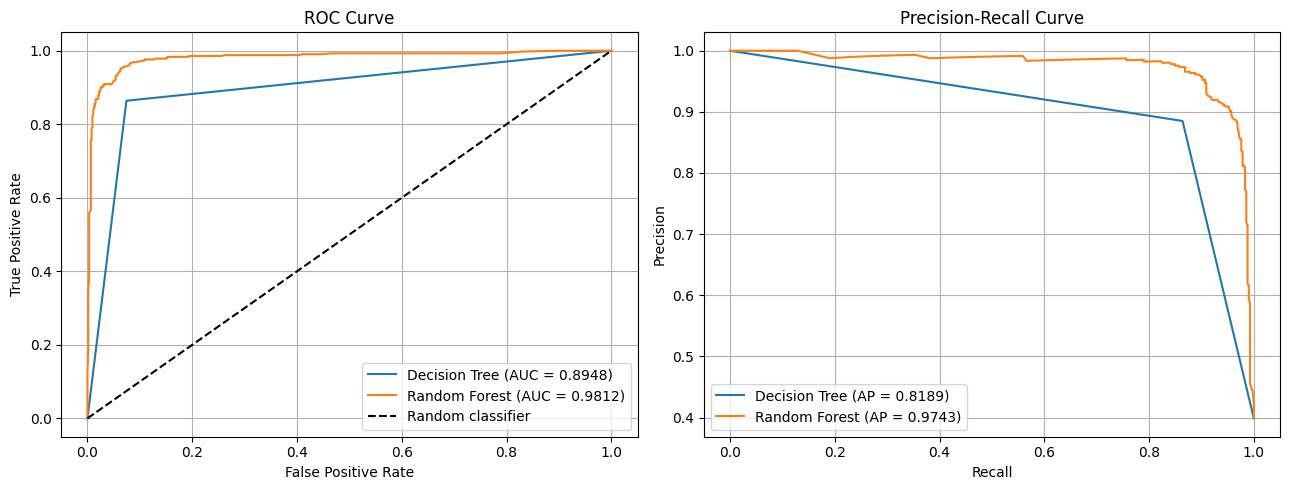

Decision Tree:
  ROC AUC: 0.8948
  Average Precision: 0.8189
Random Forest:
  ROC AUC: 0.9812
  Average Precision: 0.9743


In [22]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
) 

tree.fit(X_train, y_train)
rf.fit(X_train, y_train)


tree_probs = tree.predict_proba(X_test)[:, 1]
rf_probs = rf.predict_proba(X_test)[:, 1]


model_probs = {
    "Decision Tree": tree_probs,
    "Random Forest": rf_probs
}


fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, probs in model_probs.items():

    
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)

    axes[0].plot(
        fpr, tpr,
        label=f"{name} (AUC = {auc:.4f})"
    )

    
    precision, recall, _ = precision_recall_curve(
        y_test, probs
    )

    ap = average_precision_score(y_test, probs)

    axes[1].plot(
        recall, precision,
        label=f"{name} (AP = {ap:.4f})"
    )

# ROC plot
axes[0].plot([0, 1], [0, 1], "k--", label="Random classifier")
axes[0].set_title("ROC Curve")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()
axes[0].grid(True)

# Precision-Recall plot
axes[1].set_title("Precision-Recall Curve")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


for name, probs in model_probs.items():
    print(f"{name}:")
    print(f"  ROC AUC: {roc_auc_score(y_test, probs):.4f}")
    print(f"  Average Precision: {average_precision_score(y_test, probs):.4f}")

Decision Tree had a ROC AUC of 0.8948 and an Average Precision of 0.8189. Random Forest had higher results: 0.9812 and 0.9743.

This means Random Forest is better at finding spam emails and separating them from normal emails.

Overall, Random Forest performed better than Decision Tree. However, we still need to choose a threshold to reduce the number of normal emails marked as spam.

## Step 2.2 — Choosing a Threshold Using Out-of-Fold Predictions

In [23]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_curve
import numpy as np


oof = cross_val_predict(
    rf,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

# Calculate FPR, recall and thresholds
fpr, recall, thresholds = roc_curve(
    y_train,
    oof,
    drop_intermediate=False
)

# Keep thresholds with FPR <= 1%
valid = np.where(fpr <= 0.01)[0]

# Find the highest recall
best_recall = np.max(recall[valid])

# If tied, choose the largest threshold
candidates = valid[recall[valid] == best_recall]
best_idx = candidates[np.argmax(thresholds[candidates])]

t = thresholds[best_idx]

print(f"Selected threshold: {t:.6f}")
print(f"OOF False Positive Rate: {fpr[best_idx]:.4f}")
print(f"OOF Recall: {recall[best_idx]:.4f}")

Selected threshold: 0.753333
OOF False Positive Rate: 0.0095
OOF Recall: 0.8059


I used out-of-fold predictions from Random Forest to choose a threshold.

I selected threshold was 0.753333. The False Positive Rate was 0.95%, which is below our 1% limit. The recall was 80.59%, meaning the model detected about 81% of spam emails.



## Step 2.3 — Applying the Threshold to the Test Set

In [24]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score


y_pred_threshold = (rf_probs >= t).astype(int)


tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred_threshold, labels=[0, 1]
).ravel()


precision = precision_score(y_test, y_pred_threshold, zero_division=0)
recall = recall_score(y_test, y_pred_threshold, zero_division=0)
test_fpr = fp / (fp + tn)

print("Confusion Matrix:")
print("                 Predicted Normal   Predicted Spam")
print(f"Actual Normal       {tn:5d}             {fp:5d}")
print(f"Actual Spam         {fn:5d}             {tp:5d}")

print(f"\nPrecision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"False Positive Rate: {test_fpr:.4f}")

print(f"\nLegitimate emails flagged as spam: {fp} out of {fp + tn}")
print(f"1% target achieved: {test_fpr <= 0.01}")

Confusion Matrix:
                 Predicted Normal   Predicted Spam
Actual Normal         627                 5
Actual Spam           101               318

Precision: 0.9845
Recall: 0.7589
False Positive Rate: 0.0079

Legitimate emails flagged as spam: 5 out of 632
1% target achieved: True


The precision was 98.45%, and the recall was 75.89%. This means that most emails marked as spam were actually spam, but the model missed some spam emails.

Only 5 out of 632 legitimate emails were incorrectly marked as spam. The False Positive Rate was 0.79%, which is below our 1% limit.

Therefore, the model achieved the 1% target on the test set.

## Step 2.4 — Feature Importances

In [28]:
from sklearn.inspection import permutation_importance
import pandas as pd

perm = permutation_importance(
    rf,
    X_test,
    y_test,
    n_repeats=10,
    random_state=SEED,
    scoring="accuracy"
)
feature_names = pd.read_csv("data/spambase.csv").drop(columns=["spam"]).columns


impurity_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf.feature_importances_
}).sort_values("Importance", ascending=False).head(5)

permutation_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": perm.importances_mean
}).sort_values("Importance", ascending=False).head(5)

print("Top 5 Impurity Importances:")
print(impurity_df.to_string(index=False))

print("\nTop 5 Permutation Importances:")
print(permutation_df.to_string(index=False))

Top 5 Impurity Importances:
                   Feature  Importance
          char_freq_exclam    0.114085
          char_freq_dollar    0.087027
          word_freq_remove    0.084521
            word_freq_free    0.072729
capital_run_length_average    0.064956

Top 5 Permutation Importances:
         Feature  Importance
word_freq_remove    0.031399
char_freq_exclam    0.019125
    word_freq_hp    0.014748
char_freq_dollar    0.010752
  word_freq_free    0.009039


In impurity importance, char_freq_exclam was the most important feature (0.1141). In permutation importance, word_freq_remove was the most important (0.0314).

The rankings are different because impurity importance measures how much a feature helps the trees make better splits. Permutation importance measures how much accuracy decreases when the feature is shuffled.

For example, word_freq_hp is in the top five for permutation importance but not for impurity importance. This means it has a stronger effect on test accuracy than its impurity ranking suggests.

# Part 3 — Voting 

## Step 3.1 — Implementing Hard Voting

In [29]:
import numpy as np

def hard_vote(predictions, weights=None):
    predictions = np.asarray(predictions, dtype=int)

    n_models, n_samples = predictions.shape

    if weights is None:
        weights = np.ones(n_models)
    else:
        weights = np.asarray(weights)

    result = []

    for i in range(n_samples):
        votes = np.zeros(np.max(predictions[:, i]) + 1)

        for j in range(n_models):
            votes[predictions[j, i]] += weights[j]

        result.append(np.argmax(votes))

    return np.array(result, dtype=int)


predictions = [
    [0, 1, 1, 0],
    [1, 1, 0, 0],
    [1, 0, 1, 0]
]

print("Hard Voting:", hard_vote(predictions))

Hard Voting: [1 1 1 0]


I created a hard voting function that combines predictions from different models.

Each model votes for a class, and the class with the most votes is selected. If there is a tie, the smaller class label is chosen.

## Step 3.2 — Comparing Hard Voting with VotingClassifier

In [30]:
from sklearn.base import clone
from sklearn.ensemble import VotingClassifier
import numpy as np
import pandas as pd

fitted_members = [
    clone(model).fit(X_train, y_train)
    for name, model in members
]

member_predictions = np.array([
    model.predict(X_test)
    for model in fitted_members
])

manual_predictions = hard_vote(member_predictions)

voting_hard = VotingClassifier(
    estimators=members,
    voting="hard"
)

voting_hard.fit(X_train, y_train)

sklearn_predictions = voting_hard.predict(X_test)

print("Manual Hard Voting Accuracy:",
      np.mean(manual_predictions == y_test))

print("VotingClassifier Accuracy:",
      np.mean(sklearn_predictions == y_test))

print("Predictions match:",
      np.array_equal(manual_predictions, sklearn_predictions))

names = [name for name, model in members]

disagreement = pd.DataFrame(
    index=names,
    columns=names,
    dtype=float
)

for i in range(len(names)):
    for j in range(len(names)):
        disagreement.iloc[i, j] = np.mean(
            member_predictions[i] != member_predictions[j]
        )

print("\nPairwise Disagreement:")
print(disagreement.round(4))

Manual Hard Voting Accuracy: 0.9305423406279734
VotingClassifier Accuracy: 0.9305423406279734
Predictions match: True

Pairwise Disagreement:
          lr     knn    tree
lr    0.0000  0.0533  0.0999
knn   0.0533  0.0000  0.0999
tree  0.0999  0.0999  0.0000


Our manual Hard Voting and VotingClassifier achieved the same accuracy of 93.05%.

The predictions matched exactly, which shows that our hard voting function works correctly.

The disagreement between Logistic Regression and KNN was 5.33%. The disagreement between Decision Tree and the other models was about 9.99%.

This means the models sometimes make different predictions.

## Step 3.3 — Cross-Validation Comparison

In [31]:
from sklearn.model_selection import cross_validate
from sklearn.ensemble import VotingClassifier
import numpy as np
import pandas as pd

models_voting = {
    "Logistic Regression": lr,
    "KNN": knn,
    "Decision Tree": tree,
    "Hard Voting": VotingClassifier(estimators=members, voting="hard"),
    "Soft Voting": VotingClassifier(estimators=members, voting="soft")
}

cv_results_voting = {}

for name, model in models_voting.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy"
    )["test_score"]

    cv_results_voting[name] = scores

voting_table = pd.DataFrame(cv_results_voting).T
voting_table.columns = [f"Fold {i}" for i in range(1, 6)]
voting_table["Mean"] = voting_table.mean(axis=1)
voting_table["Std"] = voting_table.iloc[:, :5].std(axis=1, ddof=0)

print(voting_table.round(4).to_string())

member_names = ["Logistic Regression", "KNN", "Decision Tree"]
best_member = max(member_names, key=lambda name: cv_results_voting[name].mean())

print("\nBest individual model:", best_member)

for name in ["Hard Voting", "Soft Voting"]:
    differences = cv_results_voting[name] - cv_results_voting[best_member]

    print(f"\n{name} vs {best_member}")
    print("Paired differences:", np.round(differences, 4))
    print(f"Mean difference: {differences.mean():.4f}")
    print(f"Std difference: {differences.std(ddof=0):.4f}")
    print("Inside fold spread:",
          abs(differences.mean()) <= differences.std(ddof=0))

                     Fold 1  Fold 2  Fold 3  Fold 4  Fold 5    Mean     Std
Logistic Regression  0.9477  0.9429  0.9366  0.9365  0.9444  0.9416  0.0044
KNN                  0.9303  0.9287  0.9160  0.9111  0.9270  0.9226  0.0076
Decision Tree        0.8875  0.9049  0.9128  0.8968  0.9143  0.9033  0.0101
Hard Voting          0.9556  0.9477  0.9429  0.9206  0.9429  0.9420  0.0116
Soft Voting          0.9477  0.9382  0.9382  0.9238  0.9429  0.9382  0.0080

Best individual model: Logistic Regression

Hard Voting vs Logistic Regression
Paired differences: [ 0.0079  0.0048  0.0063 -0.0159 -0.0016]
Mean difference: 0.0003
Std difference: 0.0087
Inside fold spread: True

Soft Voting vs Logistic Regression
Paired differences: [ 0.     -0.0048  0.0016 -0.0127 -0.0016]
Mean difference: -0.0035
Std difference: 0.0051
Inside fold spread: True


### Interpretation

I compared five models using 5-fold cross-validation.

Logistic Regression was the best individual model with 94.16% accuracy. Hard Voting achieved 94.20%, and Soft Voting achieved 93.82%.

Hard Voting was slightly better than Logistic Regression, while Soft Voting was slightly worse.

However, both differences were inside the fold spread. This means we cannot say that one method is clearly better.



# Part 4 — Stacking 

## Step 4.1 — Manual Out-of-Fold Stacking

In [35]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import StackingClassifier
from sklearn.metrics import accuracy_score
import numpy as np

Z_train = np.column_stack([
    cross_val_predict(
        model,
        X_train,
        y_train,
        cv=cv,
        method="predict_proba"
    )[:, 1]
    for name, model in members
])

fitted_base_models = [
    clone(model).fit(X_train, y_train)
    for name, model in members
]

Z_test = np.column_stack([
    model.predict_proba(X_test)[:, 1]
    for model in fitted_base_models
])

meta = LogisticRegression()
meta.fit(Z_train, y_train)

manual_stack_pred = meta.predict(Z_test)

stack = StackingClassifier(
    estimators=members,
    final_estimator=LogisticRegression(),
    cv=cv,
    stack_method="predict_proba"
)

stack.fit(X_train, y_train)
sklearn_stack_pred = stack.predict(X_test)
max_coef_diff = np.max(
    np.abs(meta.coef_ - stack.final_estimator_.coef_)
)



print("Manual Stacking Accuracy:", accuracy_score(y_test, manual_stack_pred))
print("Sklearn Stacking Accuracy:", accuracy_score(y_test, sklearn_stack_pred))
print("Predictions match:", np.array_equal(manual_stack_pred, sklearn_stack_pred))

print("\nManual Meta Weights:", meta.coef_[0])
print("Sklearn Meta Weights:", stack.final_estimator_.coef_[0])
print("Largest Absolute Coefficient Difference:", max_coef_diff)

Manual Stacking Accuracy: 0.9314938154138915
Sklearn Stacking Accuracy: 0.9314938154138915
Predictions match: True

Manual Meta Weights: [4.2203185  2.64712157 1.26937615]
Sklearn Meta Weights: [4.2203185  2.64712157 1.26937615]
Largest Absolute Coefficient Difference: 0.0


Manual Stacking and Scikit-learn Stacking achieved the same test accuracy of 93.15%.

Their predictions and meta-learner coefficients were identical. The largest absolute difference between the coefficients was 0.0.

## Step 4.2 — Comparing In-Sample and Out-of-Fold Stacking

In [33]:
Z_train_in_sample = np.column_stack([
    model.predict_proba(X_train)[:, 1]
    for model in fitted_base_models
])

meta_in_sample = LogisticRegression()
meta_in_sample.fit(Z_train_in_sample, y_train)

weights_table = pd.DataFrame({
    "Model": [name for name, model in members],
    "Out-of-Fold Weight": meta.coef_[0],
    "In-Sample Weight": meta_in_sample.coef_[0]
})

weights_table["Difference"] = (
    weights_table["In-Sample Weight"]
    - weights_table["Out-of-Fold Weight"]
)

print(weights_table.round(4).to_string(index=False))

print("\nOut-of-Fold Stacking Test Accuracy:",
      accuracy_score(y_test, manual_stack_pred))

print("In-Sample Stacking Test Accuracy:",
      accuracy_score(y_test, meta_in_sample.predict(Z_test)))

Model  Out-of-Fold Weight  In-Sample Weight  Difference
   lr              4.2203            2.0427     -2.1776
  knn              2.6471            1.8706     -0.7765
 tree              1.2694            8.2283      6.9590

Out-of-Fold Stacking Test Accuracy: 0.9314938154138915
In-Sample Stacking Test Accuracy: 0.90104662226451


I compared in-sample and out-of-fold stacking.

The Decision Tree weight increased from 1.2694 to 8.2283 when using in-sample predictions. This happened because the Decision Tree learned the training data too closely and looked more accurate than it really was.

Out-of-fold stacking achieved 93.15% test accuracy, while in-sample stacking achieved 90.10%.

This shows that out-of-fold stacking performed better and helped reduce overfitting.

## Step 4.3 — Cross-Validation Comparison

In [36]:
from sklearn.model_selection import cross_validate
from sklearn.ensemble import StackingClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
import pandas as pd
import numpy as np

models_stacking = {
    "Logistic Regression": lr,
    "Soft Voting": VotingClassifier(
        estimators=members,
        voting="soft"
    ),
    "Stacking": StackingClassifier(
        estimators=members,
        final_estimator=LogisticRegression(),
        cv=cv,
        stack_method="predict_proba"
    )
}

cv_results_stacking = {}

for name, model in models_stacking.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy"
    )["test_score"]

    cv_results_stacking[name] = scores

stacking_table = pd.DataFrame(cv_results_stacking).T
stacking_table.columns = [f"Fold {i}" for i in range(1, 6)]
stacking_table["Mean"] = stacking_table.mean(axis=1)
stacking_table["Std"] = stacking_table.iloc[:, :5].std(axis=1, ddof=0)

print(stacking_table.round(4).to_string())

comparisons = [
    ("Stacking", "Logistic Regression"),
    ("Stacking", "Soft Voting")
]

for model_a, model_b in comparisons:
    differences = (
        cv_results_stacking[model_a]
        - cv_results_stacking[model_b]
    )

    print(f"\n{model_a} vs {model_b}")
    print("Paired differences:", np.round(differences, 4))
    print(f"Mean difference: {differences.mean():.4f}")
    print(f"Std difference: {differences.std(ddof=0):.4f}")
    print(
        "Inside fold spread:",
        abs(differences.mean()) <= differences.std(ddof=0)
    )

                     Fold 1  Fold 2  Fold 3  Fold 4  Fold 5    Mean     Std
Logistic Regression  0.9477  0.9429  0.9366  0.9365  0.9444  0.9416  0.0044
Soft Voting          0.9477  0.9382  0.9382  0.9238  0.9429  0.9382  0.0080
Stacking             0.9525  0.9382  0.9414  0.9254  0.9397  0.9394  0.0086

Stacking vs Logistic Regression
Paired differences: [ 0.0048 -0.0048  0.0048 -0.0111 -0.0048]
Mean difference: -0.0022
Std difference: 0.0062
Inside fold spread: True

Stacking vs Soft Voting
Paired differences: [ 0.0048  0.      0.0032  0.0016 -0.0032]
Mean difference: 0.0013
Std difference: 0.0027
Inside fold spread: True


I compared Logistic Regression, Soft Voting, and Stacking using five-fold cross-validation.

Logistic Regression achieved the highest mean accuracy of 94.16%, followed by Stacking with 93.94% and Soft Voting with 93.82%.

Stacking performed slightly worse than Logistic Regression but slightly better than Soft Voting.

However, both paired differences were inside the fold spread. Therefore, we cannot declare a clear winner.

Overall, Stacking did not show a clear improvement over the other models.